# Task 1: Multi-Class Benchmark Classification Pipeline
## Iris Benchmark: Logistic Regression vs Decision Tree Classifier
**Datheon Machine Learning & Data Science Internship Suite**

---

### 1. Executive Summary & Problem Formulation
This project establishes a rigorous multi-class supervised learning benchmark on Ronald Fisher's historic Iris dataset.
The objective is to accurately classify three Iris flower species (`Iris setosa`, `Iris versicolor`, and `Iris virginica`)
using four physical biometric measurements:
1. `sepal_length` (cm)
2. `sepal_width` (cm)
3. `petal_length` (cm)
4. `petal_width` (cm)

We systematically compare two distinct algorithmic paradigms:
- **Logistic Regression (Softmax)**: A parametric linear model utilizing feature standardization via `StandardScaler`.
- **Decision Tree Classifier (CART)**: A non-parametric partition-based model with depth regularization.

### 2. Methodological Safeguards
- **Data Leakage Prevention**: Transformers (`StandardScaler`) are encapsulated within Scikit-learn `Pipeline` objects and fitted **strictly** on the training fold.
- **Stratified Partitioning**: Class proportions (50:50:50) are preserved exactly across train and test partitions (80:20 ratio).
- **2D Boundary Visualizer**: Visualizes a legitimate 2-feature model projection rather than fabricating a 4D hyper-surface projection.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.common.data_loader import load_dataset
from src.common.evaluation import evaluate_classification
from src.common.visualization import plot_confusion_matrix, plot_model_comparison
from src.classification.iris_pipeline import (
    prepare_iris_data,
    build_logistic_regression_pipeline,
    build_decision_tree_pipeline,
    train_and_evaluate_models,
    plot_two_feature_decision_boundary,
    predict_species,
    CLASS_NAMES,
    FEATURE_NAMES
)

%matplotlib inline


### 3. Dataset Loading, Inspection & Verification
We load the dataset using the resilient data loader, caching it locally under `data/raw/iris.csv`.


In [2]:
df, meta = load_dataset('task1_iris')
print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Data Source Used: {meta['source_used']}")
print("Missing values per column:")
print(df.isnull().sum())
df.head(10)


[INFO] Loading cached dataset for 'task1_iris' from D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\iris.csv


[INFO] Dataset 'task1_iris' validated: 150 rows, 5 cols.


Dataset Dimensions: 150 rows x 5 columns
Data Source Used: local_cache:D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\iris.csv
Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


### 4. Exploratory Data Analysis & Class Distributions
Descriptive statistics and visual inspection of feature distributions and bivariate relationships.


In [3]:
print("Summary Statistics:")
display(df.describe())

print("\nClass Distribution:")
display(df['species'].value_counts())


Summary Statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Class Distribution:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

C:\Users\vijay\AppData\Local\Temp\ipykernel_17120\3475851075.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='species', palette='Blues', ax=axes[0], edgecolor='#111827')


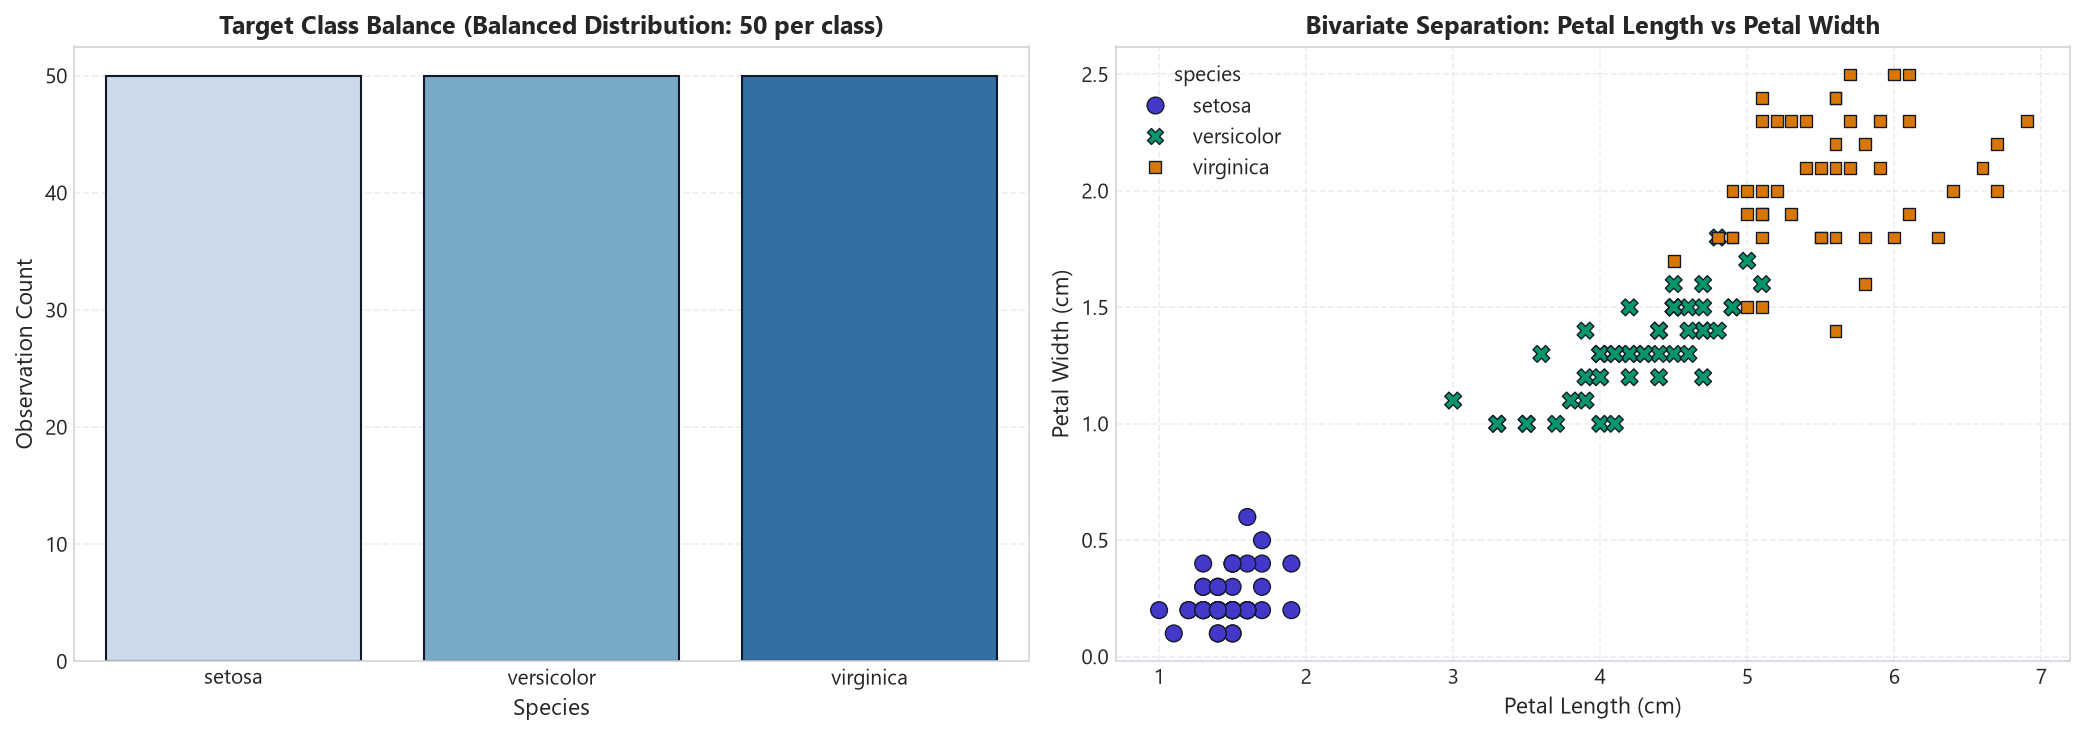

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
sns.countplot(data=df, x='species', palette='Blues', ax=axes[0], edgecolor='#111827')
axes[0].set_title('Target Class Balance (Balanced Distribution: 50 per class)', weight='bold')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Observation Count')

# Petal length vs Petal width scatter
sns.scatterplot(
    data=df, x='petal_length', y='petal_width', hue='species',
    palette=['#4338CA', '#059669', '#D97706'], style='species',
    s=65, ax=axes[1], edgecolor='#111827'
)
axes[1].set_title('Bivariate Separation: Petal Length vs Petal Width', weight='bold')
axes[1].set_xlabel('Petal Length (cm)')
axes[1].set_ylabel('Petal Width (cm)')

plt.tight_layout()
plt.show()


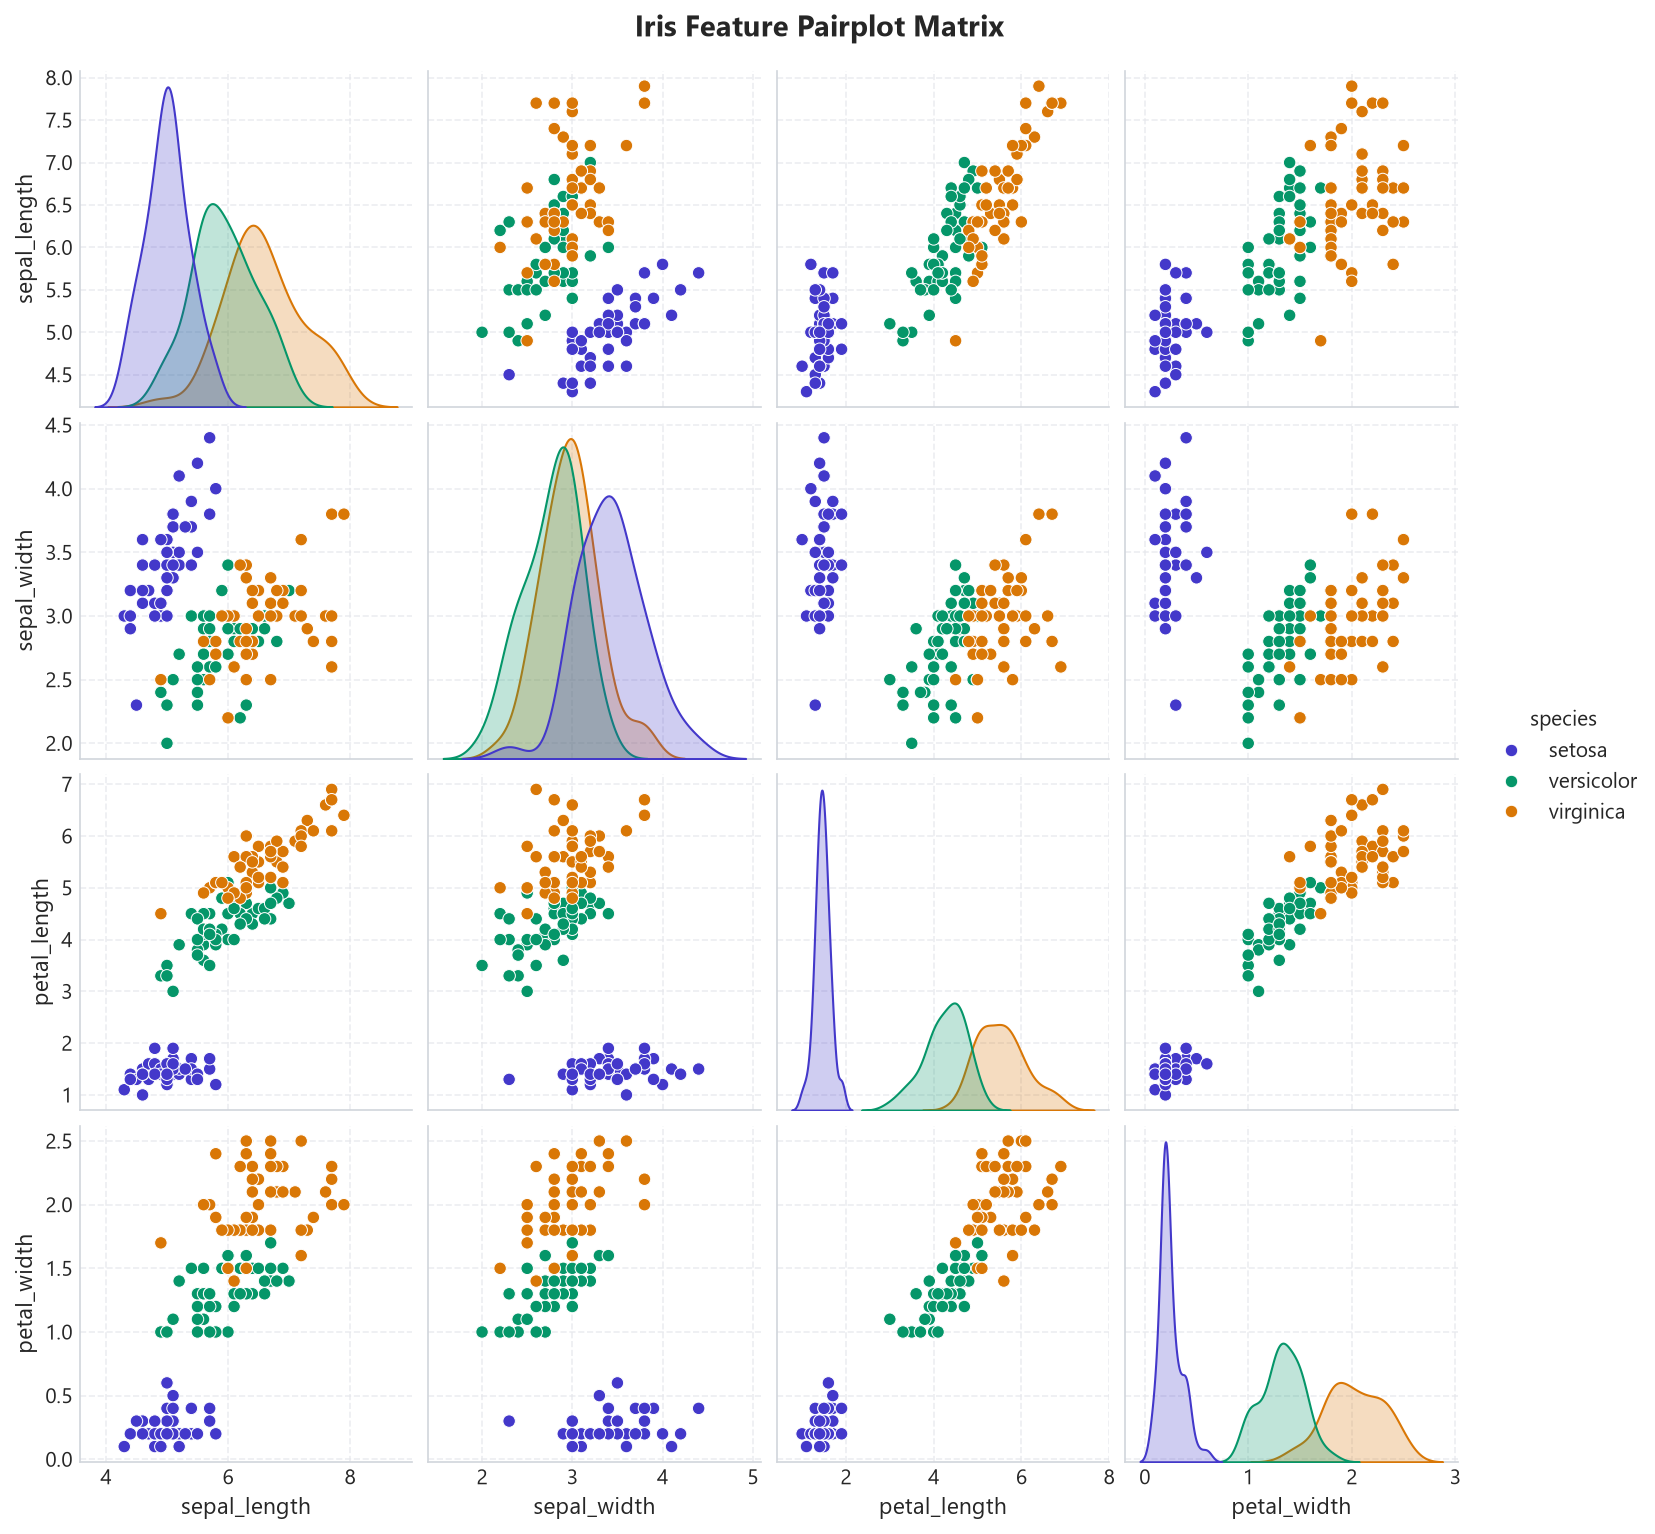

In [5]:
# Pairwise feature relationships across species
sns.pairplot(df, hue='species', palette=['#4338CA', '#059669', '#D97706'], diag_kind='kde')
plt.suptitle('Iris Feature Pairplot Matrix', y=1.02, weight='bold')
plt.show()


### 5. Stratified Train-Test Splitting & Pipeline Construction
We split the 150 instances into 120 training samples (80%) and 30 testing samples (20%) using a fixed random seed (`random_state=42`).


In [6]:
X_train, X_test, y_train, y_test, _ = prepare_iris_data(random_state=42, test_size=0.2)
print(f"Training Matrix Shape: {X_train.shape}")
print(f"Testing Matrix Shape:  {X_test.shape}")
print(f"Class counts in Test Fold: {np.bincount(y_test)} (Equally 10 per class)")


[INFO] Loading cached dataset for 'task1_iris' from D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\iris.csv


[INFO] Dataset 'task1_iris' validated: 150 rows, 5 cols.


[INFO] Iris data split: 120 train samples, 30 test samples (stratified).


Training Matrix Shape: (120, 4)
Testing Matrix Shape:  (30, 4)
Class counts in Test Fold: [10 10 10] (Equally 10 per class)


### 6. Model Training & Exhaustive Test Evaluation
Both pipelines are trained on `X_train` and evaluated strictly on `X_test`.


In [7]:
models, results = train_and_evaluate_models(X_train, X_test, y_train, y_test)

for name, metrics in results.items():
    print(f"=== {name.upper()} ===")
    print(f"Accuracy:        {metrics['accuracy']:.4f}")
    print(f"Macro Precision: {metrics['macro_precision']:.4f}")
    print(f"Macro Recall:    {metrics['macro_recall']:.4f}")
    print(f"Macro F1-Score:  {metrics['macro_f1']:.4f}\n")
    print(metrics['report_text'])
    print("-" * 55)


[INFO] Training logistic_regression pipeline on 120 samples...


[INFO] logistic_regression Results -> Accuracy: 0.9333, Macro F1: 0.9333


[INFO] Training decision_tree pipeline on 120 samples...


[INFO] decision_tree Results -> Accuracy: 0.9333, Macro F1: 0.9333


=== LOGISTIC_REGRESSION ===
Accuracy:        0.9333
Macro Precision: 0.9333
Macro Recall:    0.9333
Macro F1-Score:  0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

-------------------------------------------------------
=== DECISION_TREE ===
Accuracy:        0.9333
Macro Precision: 0.9333
Macro Recall:    0.9333
Macro F1-Score:  0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93    

### 7. Evaluation Visualizations: Confusion Matrices & Comparison Bar Chart

[WARNING] findfont: Failed to find font weight medium for Segoe UI, now using 400.


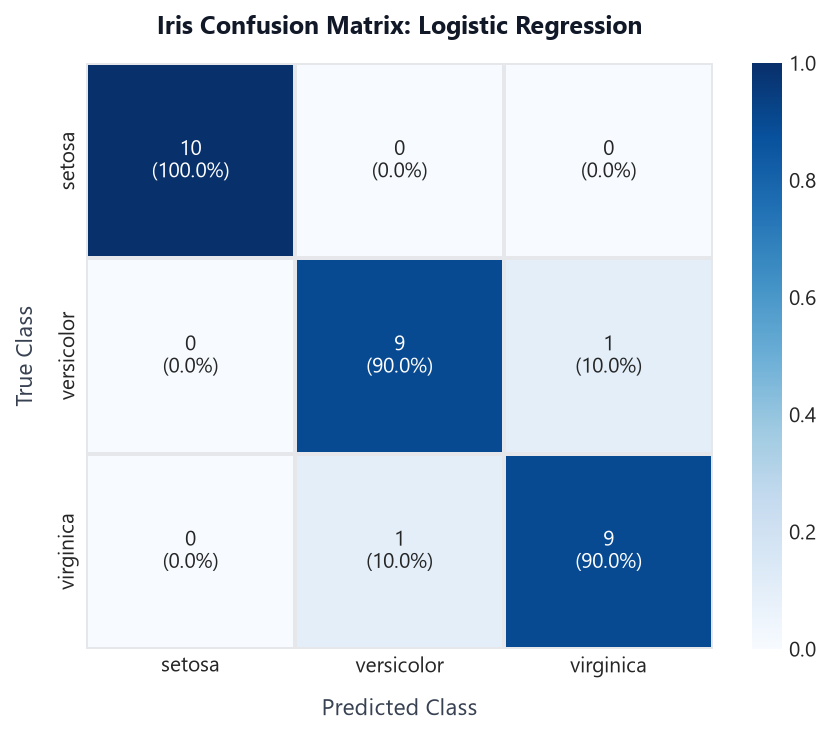

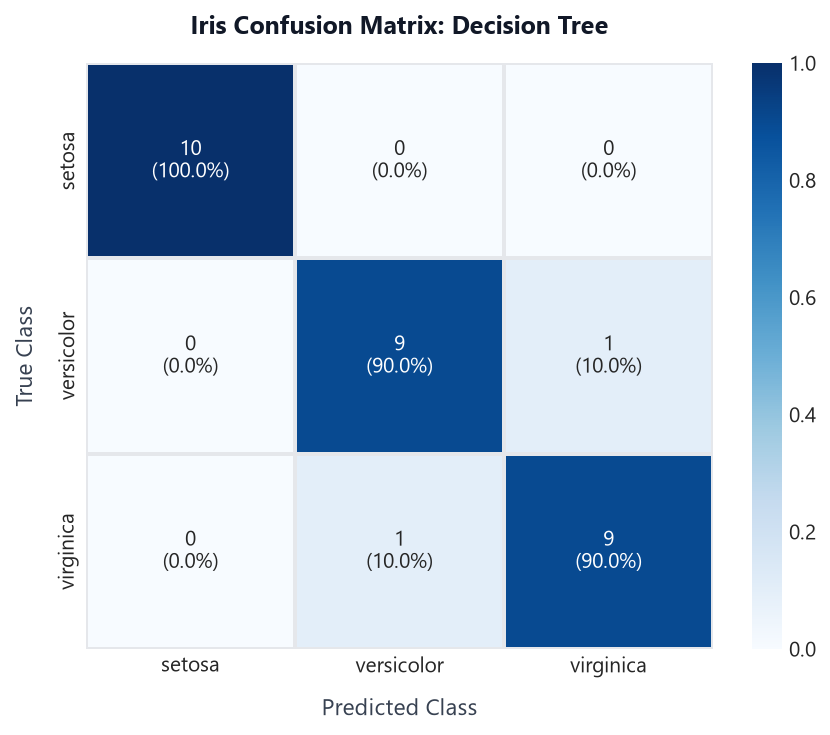

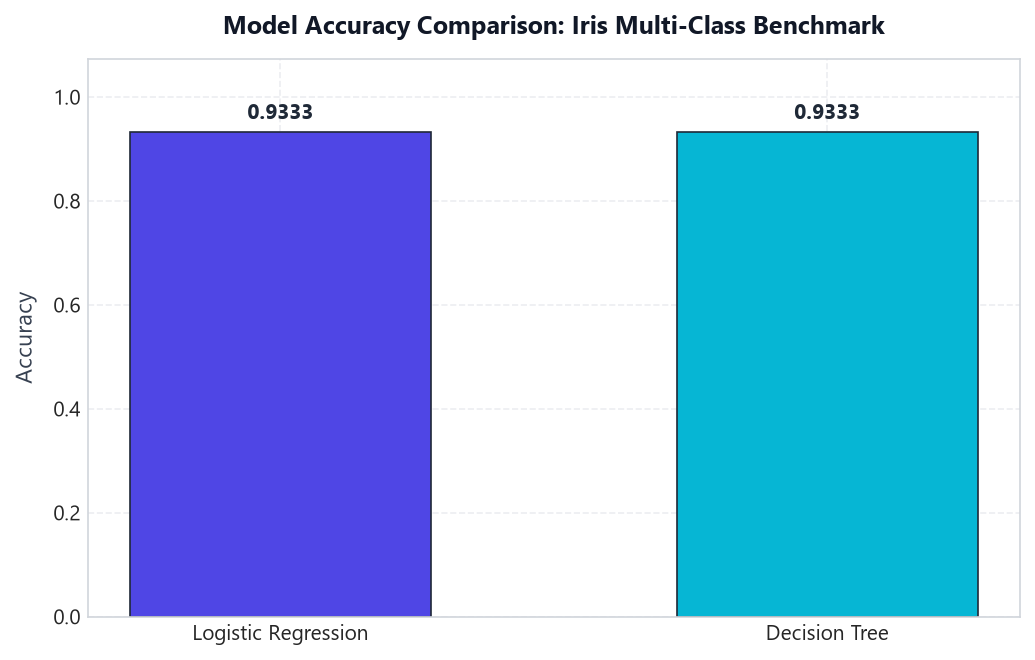

In [8]:
# Confusion Matrices
for name, metrics in results.items():
    fig = plot_confusion_matrix(
        cm=metrics['confusion_matrix'],
        class_names=CLASS_NAMES,
        title=f"Iris Confusion Matrix: {name.replace('_', ' ').title()}"
    )
    plt.show()

# Model Comparison
fig_comp = plot_model_comparison(
    models_dict={
        'Logistic Regression': results['logistic_regression']['accuracy'],
        'Decision Tree': results['decision_tree']['accuracy']
    },
    metric_name='Accuracy',
    title='Model Accuracy Comparison: Iris Multi-Class Benchmark'
)
plt.show()


### 8. Geometric Decision Boundary Analysis (2-Feature Projection)
To visualize geometric decision regions, we train dedicated 2-feature models on `sepal_length` vs `petal_length`.
**Limitation**: This visually elucidates the 2D plane decision surface. It does not falsely claim to depict the 4D hyperspace boundary.


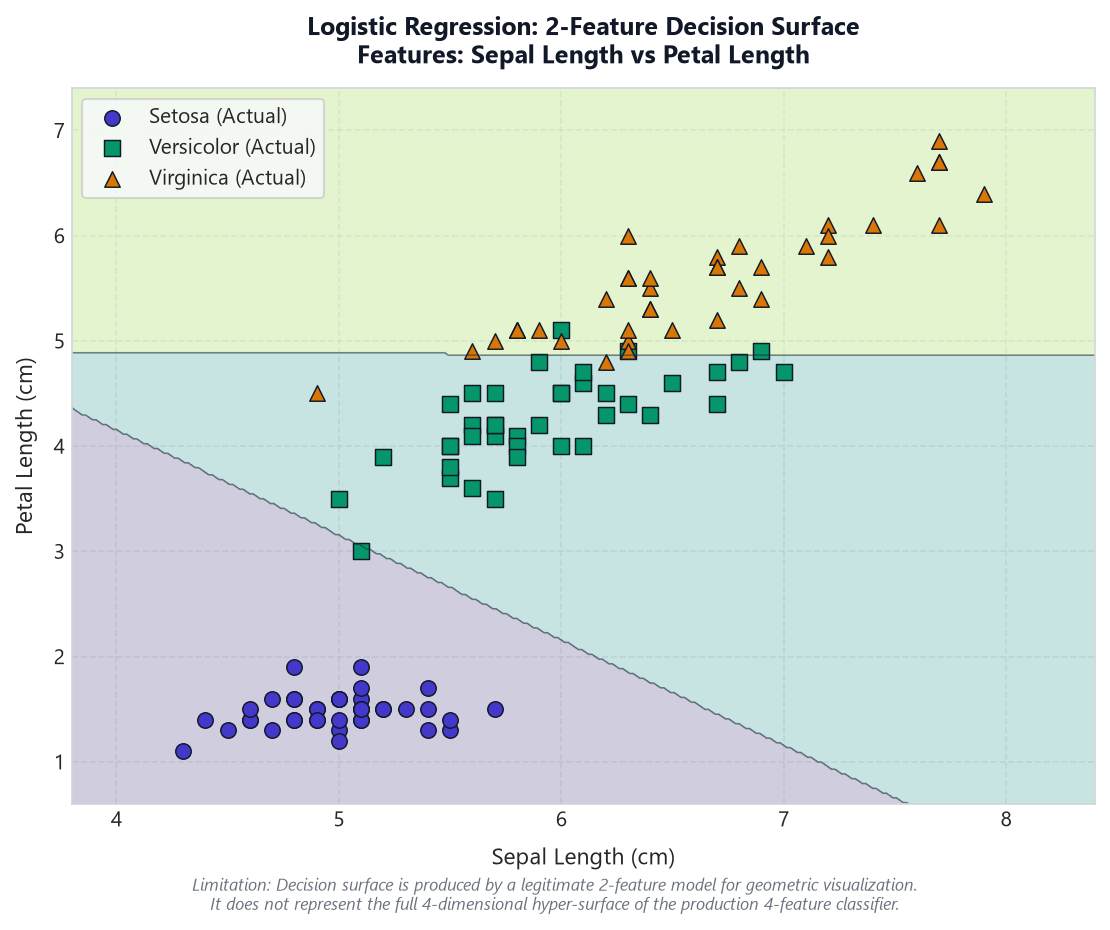

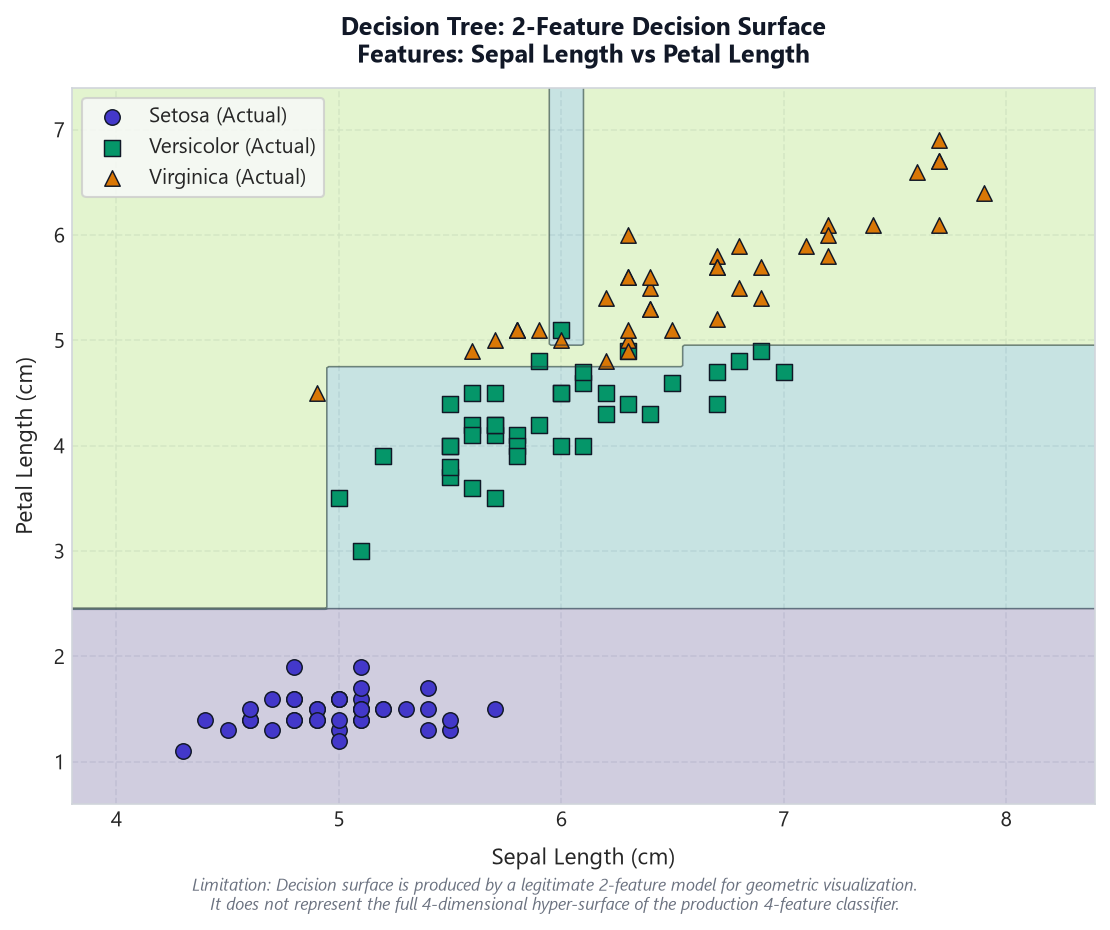

In [9]:
fig_lr = plot_two_feature_decision_boundary(
    X=X_train, y=y_train, model_type='logistic_regression', feature_indices=(0, 2)
)
plt.show()

fig_dt = plot_two_feature_decision_boundary(
    X=X_train, y=y_train, model_type='decision_tree', feature_indices=(0, 2)
)
plt.show()


### 9. Reusable Prediction Function & Real-World Inferences

In [10]:
sample_flowers = [
    [5.1, 3.5, 1.4, 0.2],  # Classic Setosa
    [6.0, 2.9, 4.5, 1.5],  # Classic Versicolor
    [6.9, 3.1, 5.4, 2.1],  # Classic Virginica
    [5.9, 3.0, 5.1, 1.8],  # Versicolor/Virginica boundary
]

print("Inference Testing with Fitted Logistic Regression Pipeline:\n")
for i, sample in enumerate(sample_flowers, 1):
    pred = predict_species(models['logistic_regression'], sample)
    print(f"Flower {i}: Measurements {sample}")
    print(f" -> Predicted: {pred['predicted_species'].upper()}")
    print(f" -> Class Probabilities: {pred['probabilities']}")
    print()


Inference Testing with Fitted Logistic Regression Pipeline:

Flower 1: Measurements [5.1, 3.5, 1.4, 0.2]
 -> Predicted: SETOSA
 -> Class Probabilities: {'setosa': 0.9808127381969137, 'versicolor': 0.019186992121989523, 'virginica': 2.696810968692031e-07}

Flower 2: Measurements [6.0, 2.9, 4.5, 1.5]
 -> Predicted: VERSICOLOR
 -> Class Probabilities: {'setosa': 0.014140139527357227, 'versicolor': 0.7594441366930891, 'virginica': 0.22641572377955368}

Flower 3: Measurements [6.9, 3.1, 5.4, 2.1]
 -> Predicted: VIRGINICA
 -> Class Probabilities: {'setosa': 0.00011014859735902453, 'versicolor': 0.08254106259761307, 'virginica': 0.9173487888050279}

Flower 4: Measurements [5.9, 3.0, 5.1, 1.8]
 -> Predicted: VIRGINICA
 -> Class Probabilities: {'setosa': 0.003971663306437958, 'versicolor': 0.31386750035736327, 'virginica': 0.6821608363361988}



### 10. Analytical Observations & Conclusions
1. **Separability**: `Iris setosa` is linearly separable from the other two species purely along petal dimensions.
2. **Algorithm Tradeoffs**:
   - Logistic Regression achieves near-perfect discrimination with smooth probabilistic confidence boundaries.
   - Decision Tree segments the feature space into orthogonal bounding boxes, susceptible to slight overfitting on boundary samples without depth pruning.
3. **Data Hygiene**: Standard scaling strictly inside the pipeline ensures test set independence and eliminates inference skew.
